<a href="https://colab.research.google.com/github/Prathamru/Data-Visualisation-Lab/blob/main/DV%20LAB%20MTECH%20PROG-3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install kagglehub pandas numpy matplotlib seaborn mplfinance

# Stock Market Time-Series Analysis

This notebook downloads daily OHLCV data and produces:

- **Candlestick charts** with SMA and EMA overlays
- **Rolling volatility bands** (Bollinger-style, ±2σ) and rolling annualized volatility
- **Volume trend plots** with up/down coloring and relative-volume analysis
- **Trend, seasonality, and significant-change analysis**
- **Correlation analysis** among return, volatility, range, and volume

Change `TICKER` and the date range in the configuration cell. If Yahoo Finance is unreachable, the notebook falls back to simulated data so the code still runs end to end.

## 1. Setup

In [2]:
# Uncomment to install dependencies
# !pip install yfinance mplfinance statsmodels pandas matplotlib numpy

import calendar
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import mplfinance as mpf
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 2. Configuration

In [3]:
TICKER = "AAPL"
START = "2018-01-01"
END = None  # None = up to today

## 3. Load data
Downloads daily prices from Yahoo Finance. Falls back to a simulated random walk if the download fails.

In [4]:
import yfinance as yf

def load_prices(ticker, start, end=None):
    df = yf.download(ticker, start=start, end=end, auto_adjust=False, progress=False)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    df = df.rename(columns=str.title)[["Open", "High", "Low", "Close", "Volume"]].dropna()
    df.index = pd.to_datetime(df.index)
    df.index.name = "Date"
    return df

try:
    data = load_prices(TICKER, START, END)
    print(f"Downloaded {TICKER} from Yahoo Finance")
except Exception as e:
    print("Download failed, using simulated data:", e)
    rng = np.random.default_rng(42)
    idx = pd.bdate_range(START, periods=1800)
    n = len(idx)
    ret = rng.normal(0.0004, 0.015, n) + 0.0002 * np.sin(2 * np.pi * np.arange(n) / 252)
    close = 100 * np.exp(np.cumsum(ret))
    openp = close * (1 + rng.normal(0, 0.004, n))
    high = np.maximum(openp, close) * (1 + np.abs(rng.normal(0, 0.006, n)))
    low = np.minimum(openp, close) * (1 - np.abs(rng.normal(0, 0.006, n)))
    vol = rng.lognormal(15, 0.4, n)
    data = pd.DataFrame({"Open": openp, "High": high, "Low": low, "Close": close, "Volume": vol}, index=idx)
    data.index.name = "Date"

print(f"{data.index[0].date()} to {data.index[-1].date()}  |  {len(data)} trading days")
data.tail()

Downloaded AAPL from Yahoo Finance
2018-01-02 to 2026-11-18  |  2233 trading days


Price,Open,High,Low,Close,Volume
Date,,,,,
2026-11-12,357.809998,359.369995,354.410004,354.880005,31875000
2026-11-13,357.959991,360.829987,355.750000,356.269989,40027500
2026-11-16,357.130005,357.130005,351.309998,352.779999,50292200
2026-11-17,352.829987,355.359985,349.670013,351.910004,37341600
2026-11-18,351.869995,356.420013,351.869995,354.355011,7265128


## 4. Feature engineering
Returns, SMA/EMA, rolling volatility, volatility bands, and volume baselines.

In [5]:
df = data.copy()

# Returns
df["Return"] = df["Close"].pct_change()
df["LogReturn"] = np.log(df["Close"]).diff()
df["AbsReturn"] = df["Return"].abs()
df["Range"] = (df["High"] - df["Low"]) / df["Close"]   # intraday range as % of close

# Moving averages
for w in (20, 50, 200):
    df[f"SMA_{w}"] = df["Close"].rolling(w).mean()
for s in (12, 26):
    df[f"EMA_{s}"] = df["Close"].ewm(span=s, adjust=False).mean()

# Rolling volatility
price_std_20 = df["Close"].rolling(20).std()
df["Vol_20"] = df["LogReturn"].rolling(20).std()          # daily
df["Vol_Ann"] = df["Vol_20"] * np.sqrt(252)               # annualized

# Volatility bands: 20-day SMA ± 2 standard deviations
df["Band_Upper"] = df["SMA_20"] + 2 * price_std_20
df["Band_Lower"] = df["SMA_20"] - 2 * price_std_20

# Volume baseline
df["Vol_SMA_20"] = df["Volume"].rolling(20).mean()
df["Vol_Ratio"] = df["Volume"] / df["Vol_SMA_20"]

df = df.dropna(subset=["SMA_200"])  # drop 200-day warm-up period
print(f"Rows after warm-up: {len(df)}")
df[["Close", "SMA_20", "EMA_12", "Vol_Ann", "Vol_Ratio"]].tail()

Rows after warm-up: 2034


Price,Close,SMA_20,EMA_12,Vol_Ann,Vol_Ratio
Date,,,,,
2026-11-12,354.880005,345.510002,347.775931,0.275357,0.661262
2026-11-13,356.269989,346.150502,349.082709,0.275319,0.847909
2026-11-16,352.779999,346.642502,349.651523,0.278234,1.047901
2026-11-17,351.910004,347.263002,349.998982,0.275360,0.776853
2026-11-18,354.355011,347.781253,350.669140,0.272836,0.155736


## 5. Candlestick chart with SMA and EMA overlays
Last 12 months, with a volume panel. Solid lines are SMAs; dashed lines are EMAs.

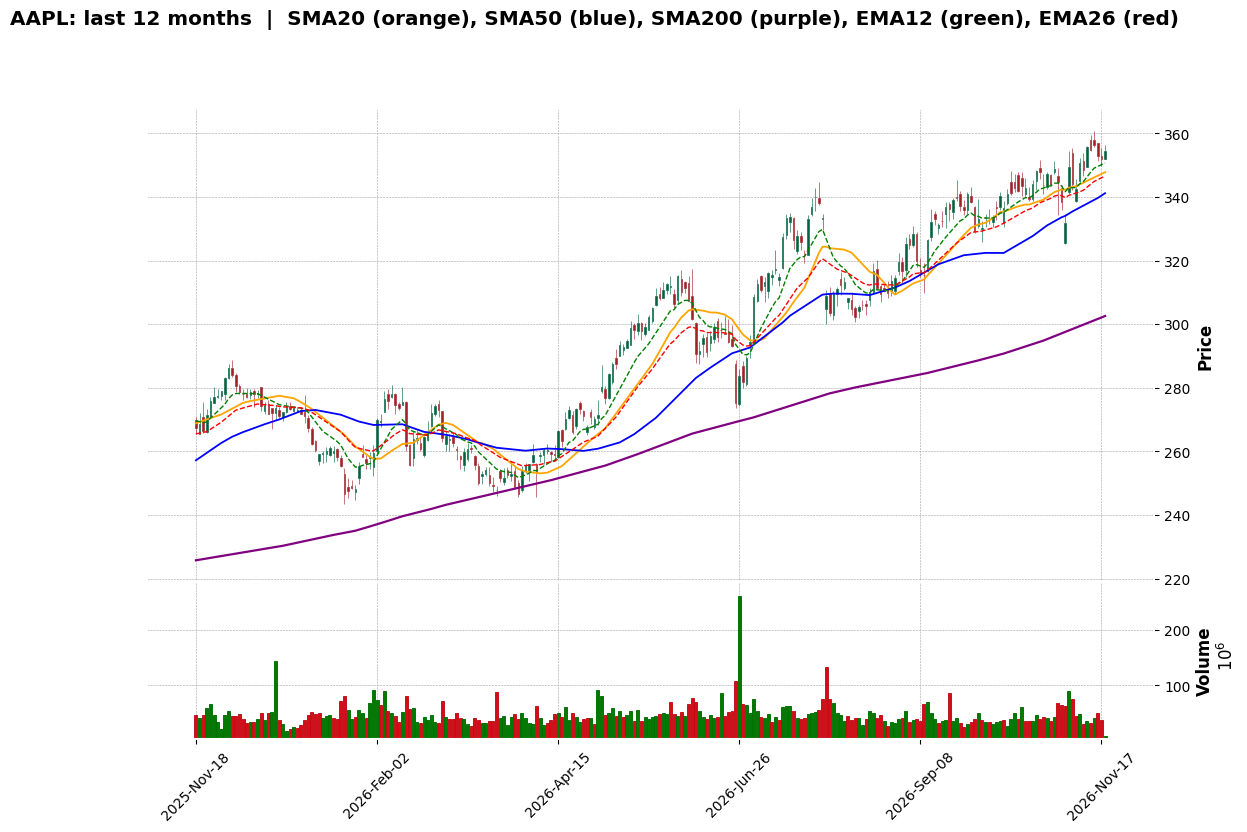

In [6]:
cutoff = df.index[-1] - pd.DateOffset(years=1)
recent = df.loc[df.index >= cutoff]

apds = [
    mpf.make_addplot(recent["SMA_20"], color="orange", width=1.3),
    mpf.make_addplot(recent["SMA_50"], color="blue", width=1.3),
    mpf.make_addplot(recent["SMA_200"], color="purple", width=1.6),
    mpf.make_addplot(recent["EMA_12"], color="green", width=1.0, linestyle="--"),
    mpf.make_addplot(recent["EMA_26"], color="red", width=1.0, linestyle="--"),
]

mpf.plot(
    recent[["Open", "High", "Low", "Close", "Volume"]],
    type="candle",
    style="charles",
    addplot=apds,
    volume=True,
    title=f"{TICKER}: last 12 months  |  SMA20 (orange), SMA50 (blue), SMA200 (purple), EMA12 (green), EMA26 (red)",
    ylabel="Price",
    ylabel_lower="Volume",
    figsize=(14, 9),
    panel_ratios=(3, 1),
)

### Full history: price with moving averages

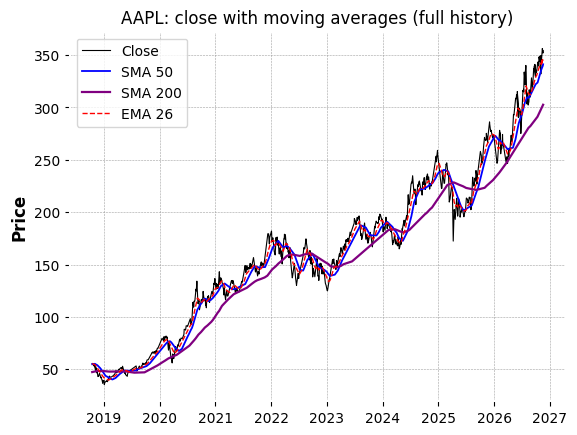

In [7]:
fig, ax = plt.subplots()
ax.plot(df.index, df["Close"], color="black", lw=0.8, label="Close")
ax.plot(df.index, df["SMA_50"], color="blue", lw=1.3, label="SMA 50")
ax.plot(df.index, df["SMA_200"], color="purple", lw=1.6, label="SMA 200")
ax.plot(df.index, df["EMA_26"], color="red", lw=1.0, ls="--", label="EMA 26")
ax.set_title(f"{TICKER}: close with moving averages (full history)")
ax.set_ylabel("Price")
ax.legend()
plt.show()

## 6. Rolling volatility bands and volatility regime
The top panel shows price inside ±2σ bands around the 20-day SMA. The bottom panel shows rolling annualized volatility, which highlights stress periods.

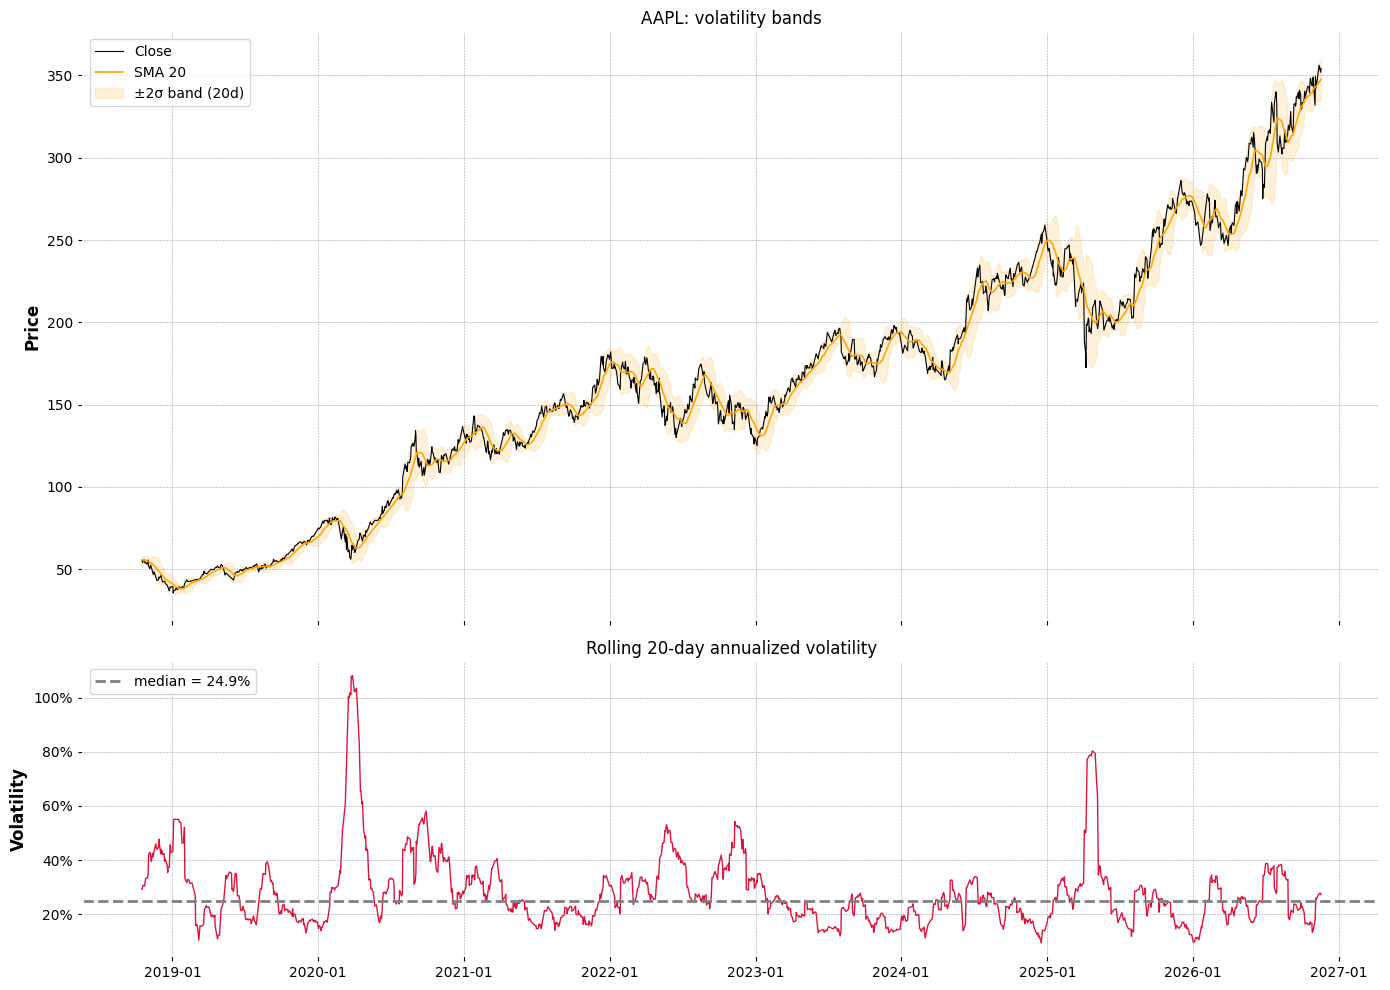

In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(14, 10),
                               gridspec_kw={"height_ratios": [2, 1]})

ax1.plot(df.index, df["Close"], color="black", lw=0.8, label="Close")
ax1.plot(df.index, df["SMA_20"], color="orange", lw=1.2, label="SMA 20")
ax1.fill_between(df.index, df["Band_Lower"], df["Band_Upper"],
                 color="orange", alpha=0.15, label="±2σ band (20d)")
ax1.set_title(f"{TICKER}: volatility bands")
ax1.set_ylabel("Price")
ax1.legend(loc="upper left")

ax2.plot(df.index, df["Vol_Ann"], color="crimson", lw=1)
ax2.axhline(df["Vol_Ann"].median(), color="gray", ls="--", label=f"median = {df['Vol_Ann'].median():.1%}")
ax2.set_title("Rolling 20-day annualized volatility")
ax2.set_ylabel("Volatility")
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax2.legend(loc="upper left")
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.tight_layout()
plt.show()

## 7. Volume trend plots
Top: daily volume colored by day direction, with a 20-day average. Bottom: volume relative to its 20-day average. Values above 1 mark unusually heavy trading.

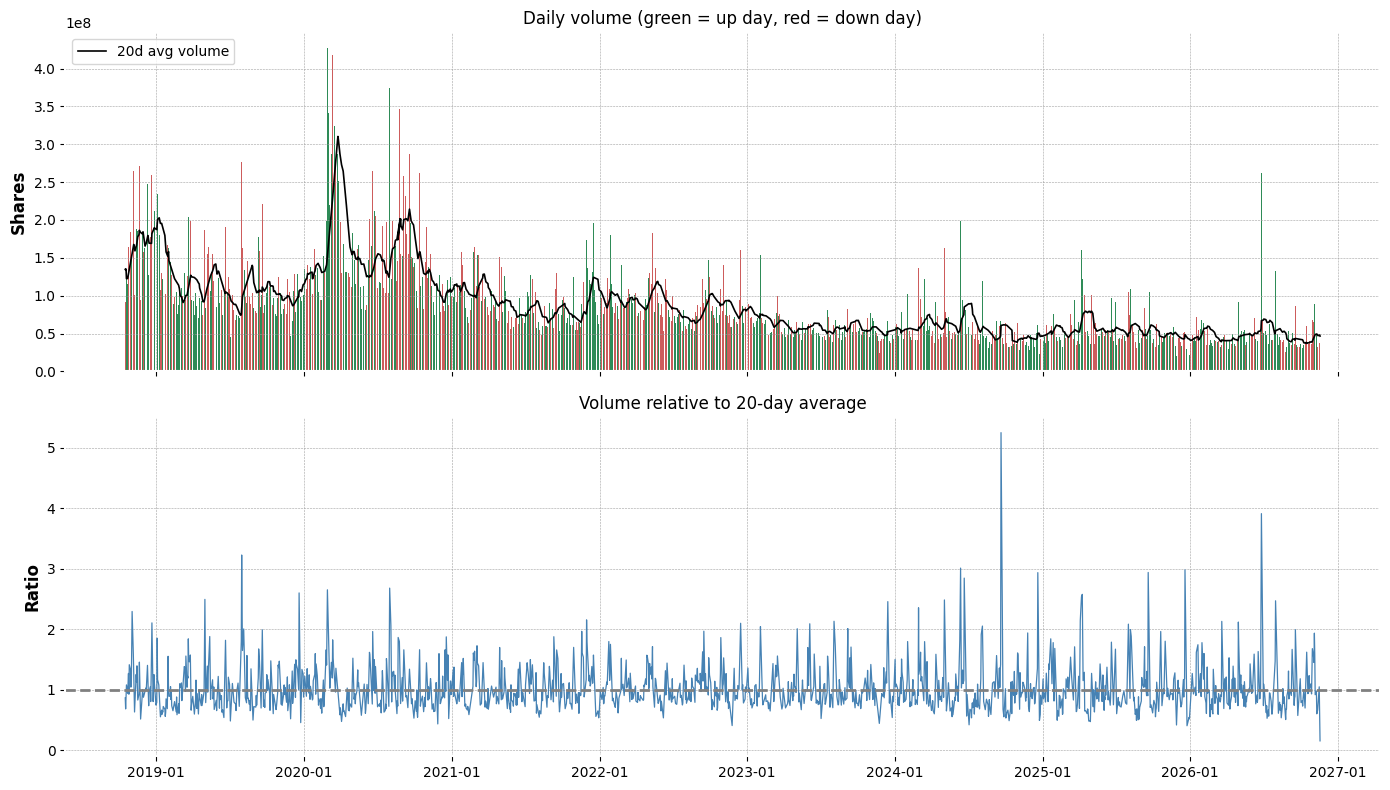

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(14, 8),
                               gridspec_kw={"height_ratios": [1, 1]})

colors = np.where(df["Close"] >= df["Open"], "seagreen", "indianred")
ax1.bar(df.index, df["Volume"], color=colors, width=1.0)
ax1.plot(df.index, df["Vol_SMA_20"], color="black", lw=1.2, label="20d avg volume")
ax1.set_title("Daily volume (green = up day, red = down day)")
ax1.set_ylabel("Shares")
ax1.legend(loc="upper left")

ax2.plot(df.index, df["Vol_Ratio"], color="steelblue", lw=0.9)
ax2.axhline(1, color="gray", ls="--")
ax2.set_title("Volume relative to 20-day average")
ax2.set_ylabel("Ratio")
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.tight_layout()
plt.show()

## 8. Long-term trend
A log-linear regression on price gives a constant compound growth rate. The R² shows how well a single trend line fits.

Log-linear trend: 22.4% per year (annualized), R² = 0.878


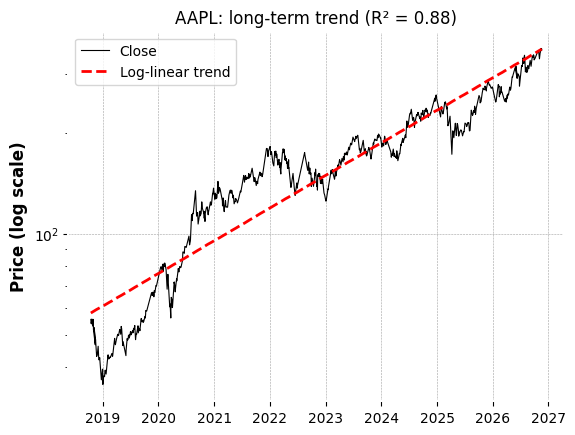

In [10]:
t = np.arange(len(df))
X = sm.add_constant(t)
model = sm.OLS(np.log(df["Close"]).values, X).fit()

slope_ann = model.params[1] * 252
print(f"Log-linear trend: {slope_ann:.1%} per year (annualized), R² = {model.rsquared:.3f}")

fig, ax = plt.subplots()
ax.plot(df.index, df["Close"], color="black", lw=0.8, label="Close")
ax.plot(df.index, np.exp(model.predict(X)), color="red", ls="--", label="Log-linear trend")
ax.set_title(f"{TICKER}: long-term trend (R² = {model.rsquared:.2f})")
ax.set_yscale("log")
ax.set_ylabel("Price (log scale)")
ax.legend()
plt.show()

## 9. Significant changes
Days where the log return is more than 3 standard deviations from the mean. These are candidates for news shocks, earnings reactions, or structural breaks.

32 days with |z| > 3


Price,Close,Return,z_score
Date,,,
2020-03-16,60.552502,-0.128647,-7.124456
2019-01-03,35.547501,-0.099607,-5.439639
2020-03-12,62.057499,-0.098755,-5.390992
2025-04-03,203.190002,-0.092456,-5.033077
2020-09-03,120.879997,-0.080061,-4.335916
2020-03-09,66.542503,-0.079092,-4.281824
2026-07-31,308.910004,-0.073539,-3.972841
2025-04-04,188.380005,-0.072887,-3.936730
2020-09-08,112.820000,-0.067295,-3.627659


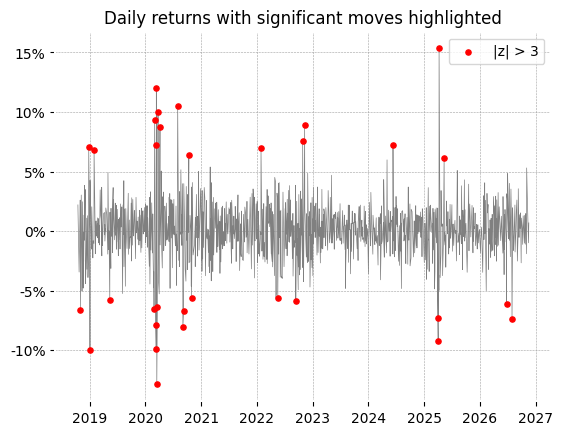

In [11]:
z = (df["LogReturn"] - df["LogReturn"].mean()) / df["LogReturn"].std()
mask = z.abs() > 3

events = df.loc[mask, ["Close", "Return"]].assign(z_score=z[mask]).sort_values("z_score")
print(f"{mask.sum()} days with |z| > 3")
display(events.head(10))

fig, ax = plt.subplots()
ax.plot(df.index, df["Return"], color="gray", lw=0.5)
ax.scatter(df.index[mask], df.loc[mask, "Return"], color="red", s=14, zorder=3, label="|z| > 3")
ax.set_title("Daily returns with significant moves highlighted")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend()
plt.show()

## 10. Seasonality
Three views: a monthly return heatmap, average return by calendar month, and an additive decomposition of monthly log prices into trend, seasonal, and residual components.

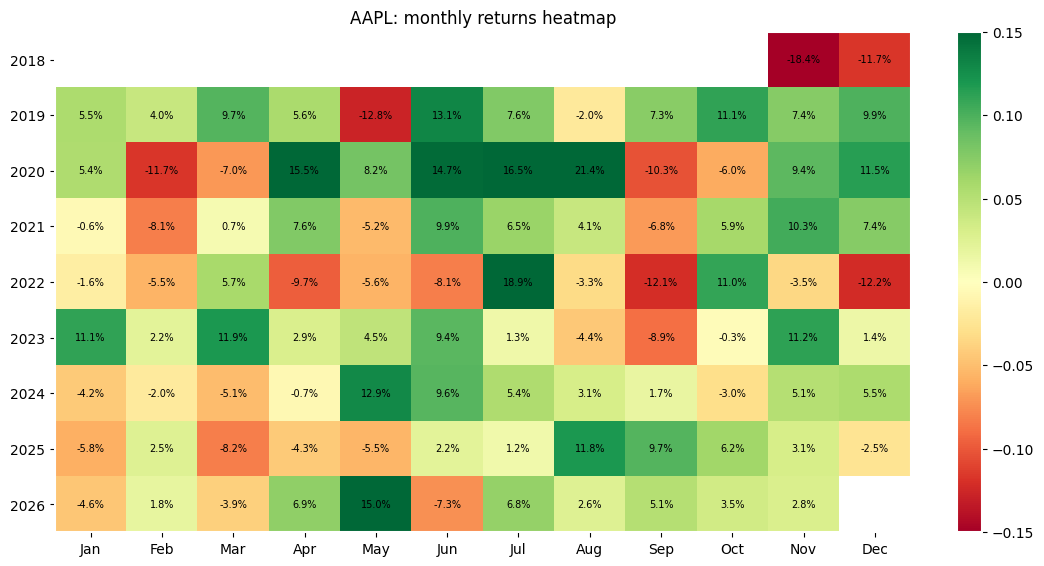

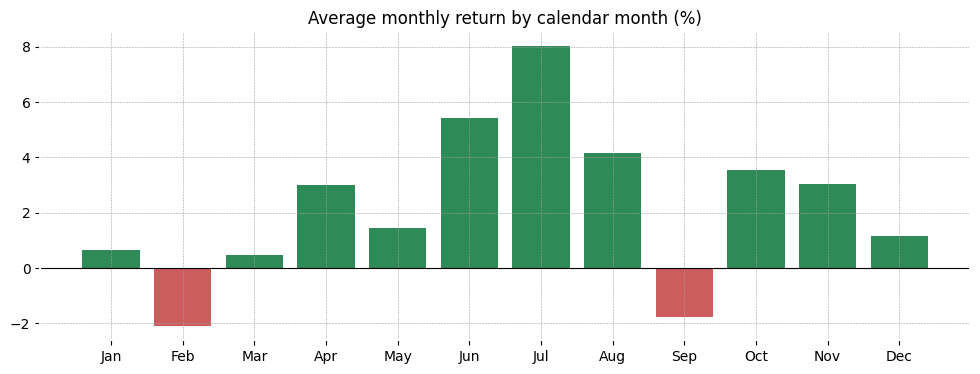

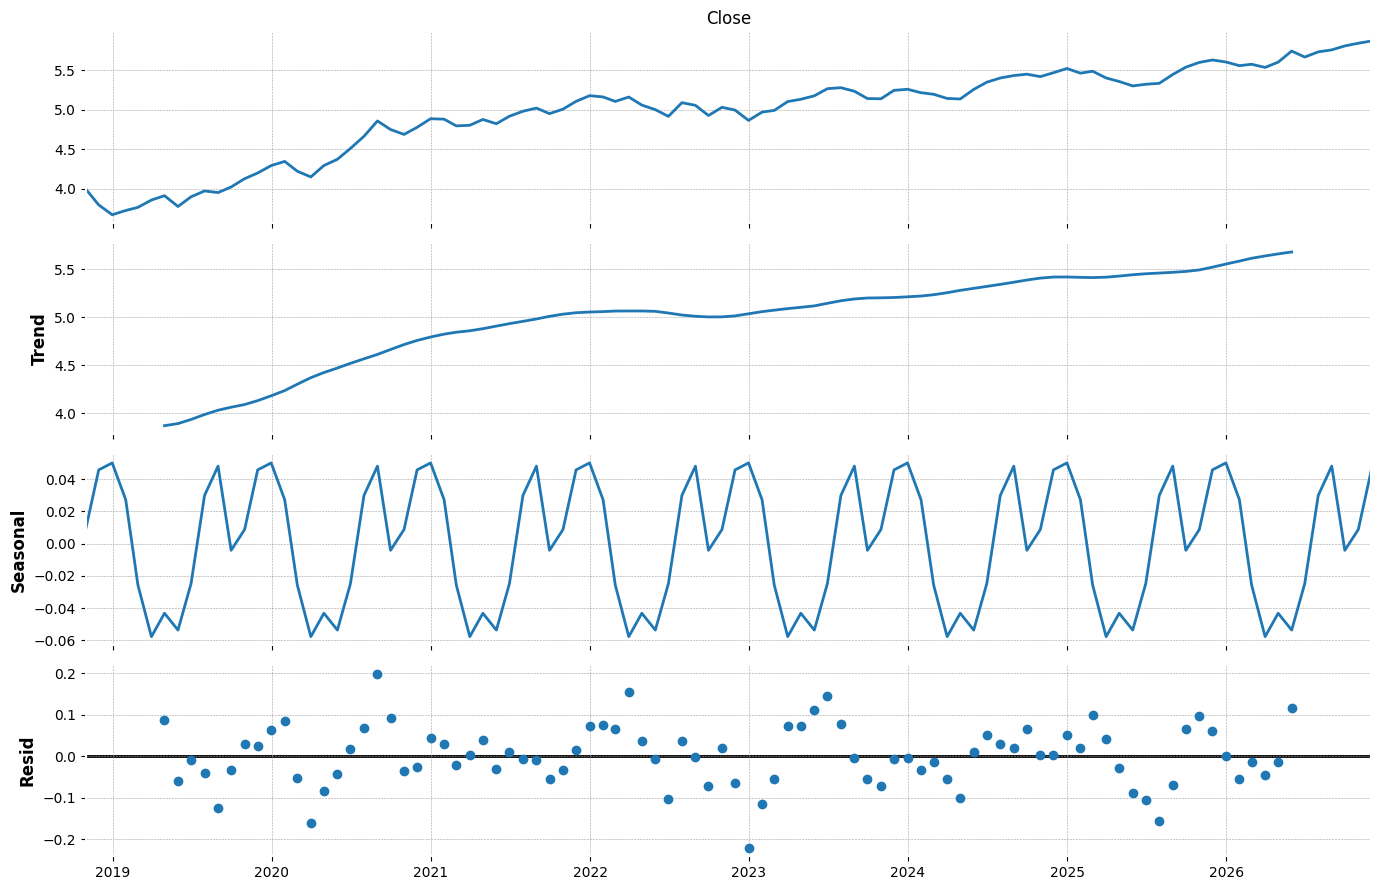

In [12]:
monthly = df["Close"].resample("M").last()
mret = monthly.pct_change().dropna()

# (a) Heatmap of monthly returns by year and month
heat = (mret.to_frame("ret")
        .assign(year=lambda x: x.index.year, month=lambda x: x.index.month)
        .pivot(index="year", columns="month", values="ret"))

fig, ax = plt.subplots(figsize=(12, 0.5 * len(heat) + 2))
im = ax.imshow(heat.values, cmap="RdYlGn", aspect="auto", vmin=-0.15, vmax=0.15)
ax.set_xticks(range(len(heat.columns)))
ax.set_xticklabels([calendar.month_abbr[m] for m in heat.columns])
ax.set_yticks(range(len(heat)))
ax.set_yticklabels(heat.index)
ax.grid(False)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1%}", ha="center", va="center", fontsize=7)
ax.set_title(f"{TICKER}: monthly returns heatmap")
fig.colorbar(im, ax=ax, fraction=0.03)
plt.show()

# (b) Average return by calendar month
mavg = mret.groupby(mret.index.month).mean() * 100
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar([calendar.month_abbr[m] for m in mavg.index], mavg.values,
       color=np.where(mavg.values >= 0, "seagreen", "indianred"))
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Average monthly return by calendar month (%)")
plt.show()

# (c) Seasonal decomposition of monthly log price
decomp = seasonal_decompose(np.log(monthly), model="additive", period=12)
fig = decomp.plot()
fig.set_size_inches(14, 9)
plt.tight_layout()
plt.show()

## 11. Relationships among variables
Correlations between returns, absolute returns, volatility, intraday range, and relative volume. High correlation between absolute returns and volume is typical: large price moves attract heavier trading.

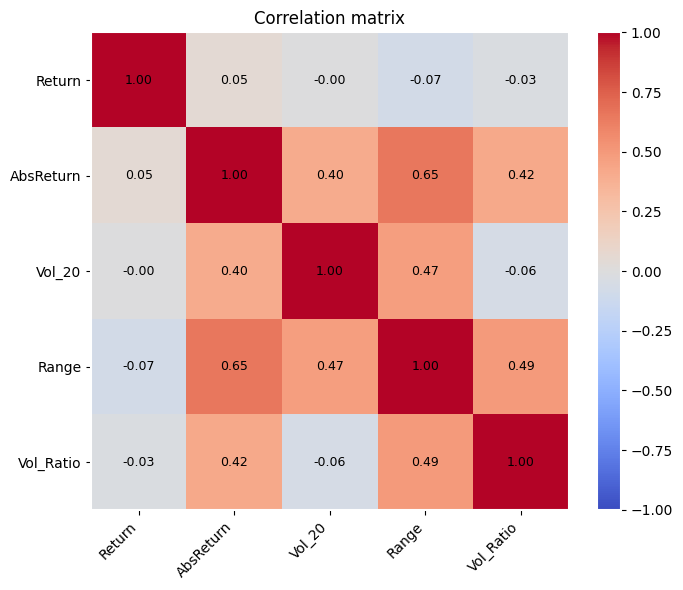

In [13]:
cols = ["Return", "AbsReturn", "Vol_20", "Range", "Vol_Ratio"]
corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticklabels(cols)
ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Correlation matrix")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

## 12. Summary statistics

In [14]:
years = (df.index[-1] - df.index[0]).days / 365.25
total_ret = df["Close"].iloc[-1] / df["Close"].iloc[0] - 1
cagr = (1 + total_ret) ** (1 / years) - 1
ann_vol = df["LogReturn"].std() * np.sqrt(252)
mean_ann = df["LogReturn"].mean() * 252
drawdown = df["Close"] / df["Close"].cummax() - 1

summary = pd.Series({
    "Period": f"{df.index[0].date()} to {df.index[-1].date()}",
    "Total return": f"{total_ret:.1%}",
    "CAGR": f"{cagr:.1%}",
    "Annualized volatility": f"{ann_vol:.1%}",
    "Return / volatility (rf = 0)": f"{mean_ann / ann_vol:.2f}",
    "Max drawdown": f"{drawdown.min():.1%}",
    "Share of up days": f"{(df['Return'] > 0).mean():.1%}",
    "Days with |z| > 3": int(mask.sum()),
    "Corr(|return|, volume)": f"{df['AbsReturn'].corr(df['Volume']):.2f}",
})
summary.to_frame("Value")

,Value
Period,2018-10-16 to 2026-11-18
Total return,538.0%
CAGR,25.7%
Annualized volatility,30.9%
Return / volatility (rf = 0),0.75
Max drawdown,-36.2%
Share of up days,53.3%
Days with |z| > 3,32
"Corr(|return|, volume)",0.51


## 13. How to read the results

- **Trend:** A price above a rising SMA 200 suggests a long-term uptrend. A rising SMA 50 that crosses above SMA 200 (a "golden cross") has historically been read as a bullish signal, and the reverse as bearish. Check the log-linear R² to see how well one trend line describes the whole history.
- **EMA versus SMA:** EMAs react faster to new prices. When EMA 12 is above EMA 26, short-term momentum is positive.
- **Volatility bands:** Price touching or leaving the band is not a signal by itself. Band width shows volatility, and bands that narrow for long stretches often come before larger moves.
- **Volatility regimes:** Spikes in annualized volatility line up with sell-offs and news events. Volatility tends to cluster, so high-volatility periods usually persist for a while.
- **Volume:** Rising price on heavy volume is more convincing than rising price on light volume. A volume ratio well above 1 on a large price move often marks a real change in sentiment.
- **Seasonality:** Calendar patterns in a single stock are weak and unstable. Treat them as hypotheses to test, not as reliable forecasts.
- **Significant changes:** Days with |z| > 3 usually come from earnings or macro news. Check them against a news calendar before reading too much into them.
- **Caveat:** This is descriptive analysis of historical data, not investment advice. Past patterns do not guarantee future results.